# Practical Quantum Computing using Qiskit


<div>
<img src="https://upload.wikimedia.org/wikipedia/commons/5/51/Qiskit-Logo.svg" width="150"/>
</div>

In this workshop we will demonstrate the four steps involved in writing a Quantum Program using Qiskit:

1. Map the problem to a quantum-native format
2. Optimize the circuit
3. Execute the circuit using Quantum Primitives
4. Analyze the results

---

In [ ]:
%%capture
!pip install qiskit[visualization]==2.0.2
!pip install qiskit-aer==0.17.1
!pip install qiskit-ibm-runtime==0.40.1

## Setting up


In [ ]:
from qiskit import QuantumCircuit
from qiskit.circuit.random import random_circuit
from qiskit_ibm_runtime.fake_provider import FakeAlmadenV2
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_aer.primitives import SamplerV2
from qiskit.visualization import plot_histogram

In [ ]:
from tempfile import NamedTemporaryFile
from matplotlib import pyplot as plt
from IPython.display import HTML, display, Image
import matplotlib.animation as animation

def muestra_counts(qubit_counts):
  columnas = ['00', '01', '10', '11']
  values = [qubit_counts.get(col, 0) for col in columnas]

  plt.bar(columnas, values)
  plt.xlabel("qubits")
  plt.ylabel("counts")
  plt.show()

def plot_circuit_samples(circuito,sampler):
  fig, ax = plt.subplots()
  columnas = ['00', '01', '10', '11']
  bar_container = ax.bar(columnas, [0, 0, 0, 0])
  ax.set_xlabel("Qubits")
  ax.set_ylabel("Counts")
  ax.set_ylim(0, 600)

  def update(frame):
      job = sampler.run([circuito])
      result = job.result()
      qubit_counts = result[0].data.meas.get_counts()
      values = [qubit_counts.get(col, 0) for col in columnas]

      for bar, new_height in zip(bar_container, values):
          bar.set_height(new_height)

      return bar_container

  ani = animation.FuncAnimation(fig, update, frames=50, interval=200, blit=False)
  plt.close(fig)

  with NamedTemporaryFile("w", suffix=".gif") as animation_file:
    ani.save(animation_file.name, writer="pillow", fps=10)
    display(Image(filename=animation_file.name))

## Step 1: Map the problem from the real world to the Quantum world

In the Quantum paradigm, `quantum circuits` are the native format in which the quantum instructions are represented. A quantum circuit is a sequence of `quantum gates` that operate over the different qubits. In this section we will see how those circuits are constructed.

### Building a Quantum Circuit

In order to build a circuit, we instantiate the `QuantumCircuit` class, passing it as a parameter the number of qubits that we want to make use of.

The simplest example of a Quantum Circuit is one that does not have any gate on it:

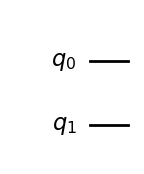

In [ ]:
from qiskit import QuantumCircuit

# Create a circuit with 2 qubits.
circuito = QuantumCircuit(2)

# Visualize the circuit.
circuito.draw("mpl")

The circuit's functionality is determined by the instructions (`gates`) that are added to its qubits. As an analogy to classical computing, they are the building blocks that allow expressing different algorithms and operations.

There are many kinds of quantum gates included in Qiskit, and in this case we are going to add a Hadamard gate to one of the qubits. The Hadamard gate (`h`) changes the state of a Qubit to a superposition of the states `0` and `1`:

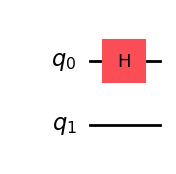

In [ ]:
# Apply a Hadamard gate to Qubit 0.
circuito.h(0)
circuito.draw("mpl")

In order to retrieve information _from_ the Quantum Circuit, it is common to make measures over one or all the qubits. Due to the Quantum nature, whenever a measure is performed about the state of a Qubit, its state is lost (collapsed).

The `measure` stores the state of the qubit at that point in time into a classical register:

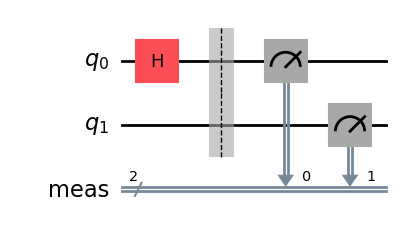

In [ ]:
# Measure the state of all the Qubits.
circuito.measure_all()
circuito.draw("mpl")

> References:
> * https://docs.quantum.ibm.com/guides/map-problem-to-circuits
> * https://docs.quantum.ibm.com/api/qiskit/qiskit.circuit.library.HGate
> * https://docs.quantum.ibm.com/api/qiskit/circuit_library

### Preparing other circuits

In order to make the next steps of the workshop easier, let's create a couple more circuits.

The second circuit adds a new `cx` gate, in order to construct a Bell state (we will look deeper into it further forward):

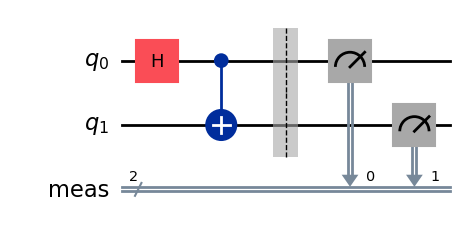

In [ ]:
circuito_bell = QuantumCircuit(2)
circuito_bell.h(0)
# Apply a controlled x gate to qubit 1, controlled by qubit 0.
circuito_bell.cx(0, 1)
circuito_bell.measure_all()

circuito_bell.draw("mpl")

The third circuit is simply a random circuit, as an example of a more complex circuit that starts resembling the circuits used in real world:

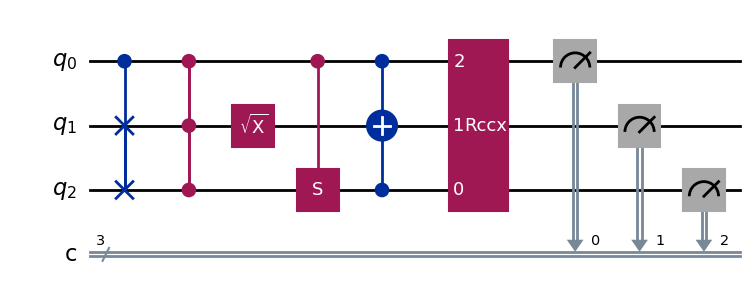

In [ ]:
from qiskit.circuit.random import random_circuit


# Genera un circuito aleatorio.
circuito_random = random_circuit(3, 5, measure=True)
circuito_random.draw("mpl")

## Step 2: Optimize the Circuit and its instructions

When the Quantum circuits are executed in a real Quantum Device, it is important to optimize the instructions that the circuit contains, minimizing the "circuit depth" (~ the number of instructions) of the circuit. This way, the characteristics of that specific device are put to use wisely, reducing the effect of error and noise.

The figure below shows the topology and features of one of our Quantum Devices, as a reference.

This optimization process is called `transpilation`, and it is highly configurable. In essence:
* the transpilation is directed by a `PassManager` - a set of optimization passes, and the logic connecting them
* each `PassManager` has a series of `stages`
* each `stage` has a series of `TranspilerPasses`
* by default, Qiskit includes several pre-defined `PassManager`s, ready to use - they can be composed and modified in order to reach the desired customized optimization


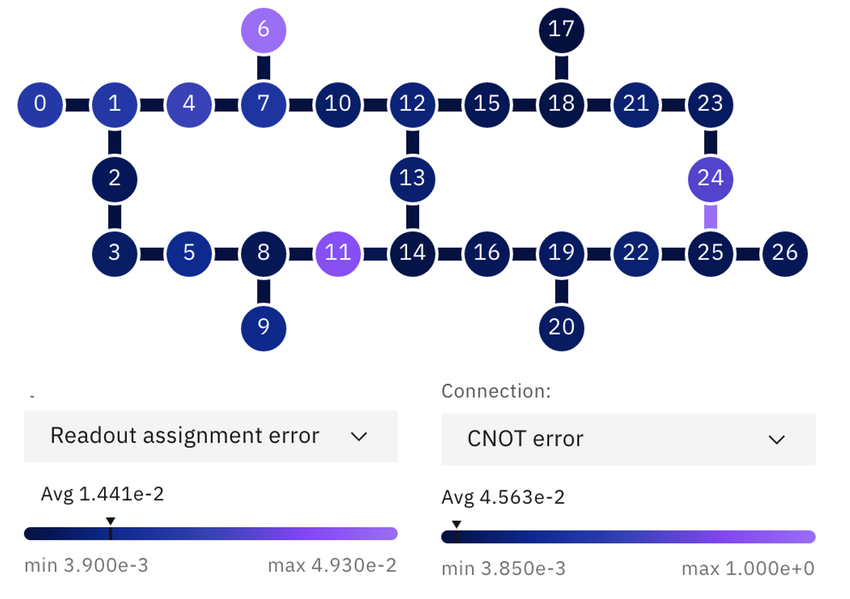

In [ ]:
from IPython.display import Image
Image("topology.png")

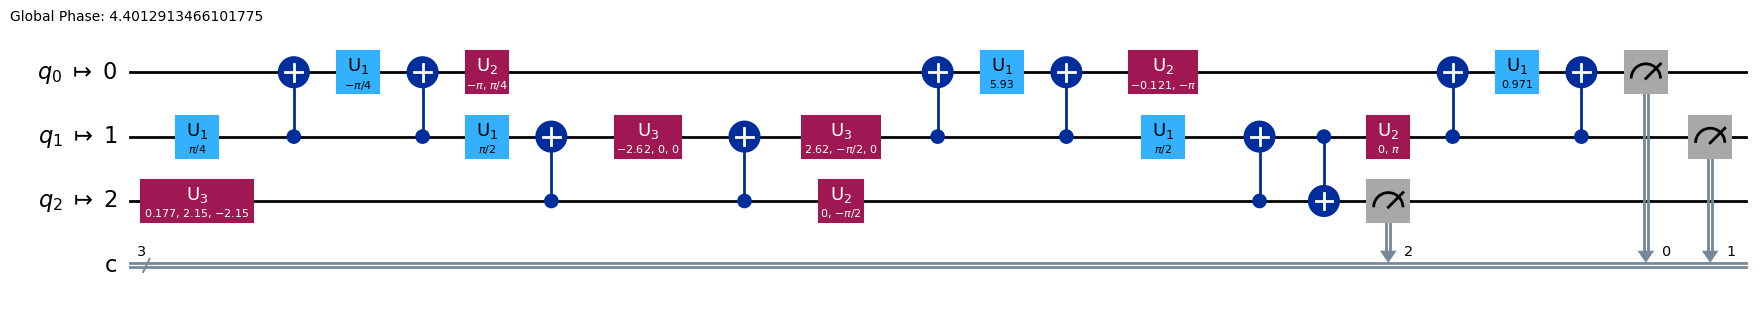

In [ ]:
from qiskit_ibm_runtime.fake_provider import FakeAlmadenV2
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# Get a reference to a backend.
backend = FakeAlmadenV2()

# Convert to an ISA circuit and layout-mapped observables.
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_circuit = pm.run(circuito_random)

isa_circuit.draw("mpl", idle_wires=False)

As you can see, the optimized circuit is less readable than the original one: it contains optimizations and transformations of different types, for example converting the high-level gates into unitary gates, taking into account the device topology, and many other operations that result in a more efficient execution in a device. El circuito optimizado suele ser menos legible que el circuito original, ya que contiene optimizaciones y transformaciones de diferentes tipos, descomponiendo puertas en puertas unitarias, teniendo en cuenta la topología del dispositivo, y muchas otras operaciones que resultan en una ejecución más eficiente en ese dispositivo (en este caso, `almaden`) específico.

> References:
> * https://docs.quantum.ibm.com/guides/optimize-for-hardware
> * https://quantum.ibm.com/services/resources


## Step 3: Execute using Primitives

Quantum computers generate non-deterministic results, and because of that an execution requires a number of repetitions (by default, 1024 times or `shots`) in order to get a meaningful result. Qiskit `Primitives` are an abstraction that represents the minimal processing unit - the simplest building block.

There are two kinds of primitives:

* `Estimator`: calculates the expected values of the  `observables`.
* `Sampler`: samples the classical registers which store the state of a qubit after executing the Quantum Circuit.

For this workshop, we will use the `sampler`, as it is slightly more intuitive.

In order to use any of the primitives, we create an instance of the corresponding class:

In [ ]:
from qiskit_aer.primitives import SamplerV2

sampler = SamplerV2()

All primitives contain a `.run()` method, that expects a `QuantumCircuit`. This method is responsible for sending the Quantum Circuit to the chosen device (or, in our case, to our local simulator), returning an identifier for that execution.

When the execution ends, this identifiers is used to retrieve the result:

In [ ]:
job = sampler.run([circuito])
job

In [ ]:
resultado = job.result()
resultado

PrimitiveResult([SamplerPubResult(data=DataBin(meas=BitArray(<shape=(), num_shots=1024, num_bits=2>)), metadata={'shots': 1024, 'circuit_metadata': {}, 'simulator_metadata': {'time_taken_parameter_binding': 2.6138e-05, 'time_taken_execute': 0.002798949, 'omp_enabled': True, 'max_gpu_memory_mb': 0, 'max_memory_mb': 12975, 'parallel_experiments': 1}})], metadata={'version': 2})

The result contains the samples that the sampler has measured, as well as a series of meta-data about the execution. Starting from the "raw" results, the next steps is about analyzing and interpreting the results.

> References:
> * https://docs.quantum.ibm.com/guides/execute-on-hardware


## Step 4: Analyze the Results

The last step of the 4-step pattern is where the post-processing and the interpretation of results happens, making use of the data obtained in the previous step for returning an answer mapped back to the classical domain.

In our example, let's consider that what we are trying to obtain is a distribution of the qubit states after the execution. We will make use of a helper function for easiness of plotting:

In [ ]:
from qiskit.visualization import plot_histogram

As we are using the `Sampler` primitive, the result has in the field `data.meas` a function that returns the number of times each execution resulted in a specific sequence of qubits:

In [ ]:
job = sampler.run([circuito])
qubit_counts_original = job.result()[0].data.meas.get_counts()
qubit_counts_original

{'01': 516, '00': 508}

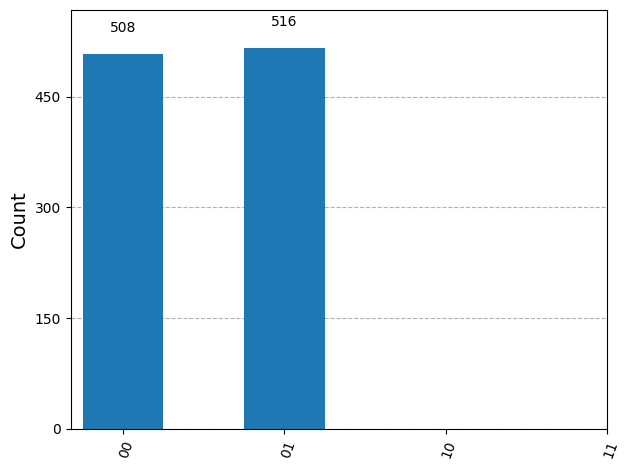

In [ ]:
plot_histogram(qubit_counts_original | {'10': 0, '11': 0})

We can see that this distribution makes sense, from the Quantum point of view:
* we applied a Hadamard gate to the first qubit (`0`), which precisely makes that its state is distributed uniformly due to superposition.
* the second qubit (`1`) does not have any gate applied, so its value is always the `0` value.

Due to the statistical nature, our execution will have a different number of counts in your notebook. To better illustrate it, in this animation we execute the same circuit a number of times, and show the different distribution:


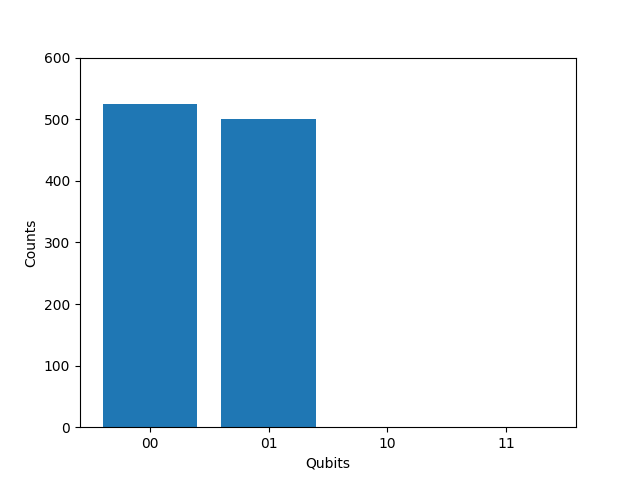

In [ ]:
plot_circuit_samples(circuito, sampler)

### Compared to the other circuit: Bell state

Going back to one of the circuits we created before (`circuito_bell`), we can observe one of the other phenomena used in Quantum Computing: entanglement.

Let's recall what the circuit looked like:

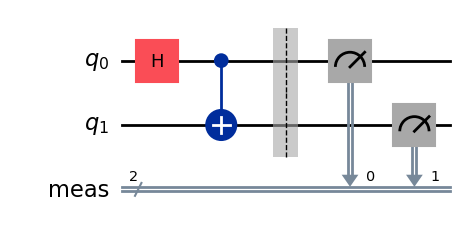

In [ ]:
circuito_bell.draw("mpl")

The difference, compared to our original circuit, is the addition of a `cx` gate. What this gate does is modifying the destination qubit (in this case, `q1`) depending on the value of the control qubit (`q0`). Through this combination of gates, a Bell state is generated: both qubits are entangled, which means that all changes in the state of one of them will be reflected in the other, independently of the distance between them.

If we execute the circuit through the sampler:

In [ ]:
job_bell = sampler.run([circuito_bell])
qubit_counts_bell = job_bell.result()[0].data.meas.get_counts()
qubit_counts_bell

{'11': 480, '00': 544}

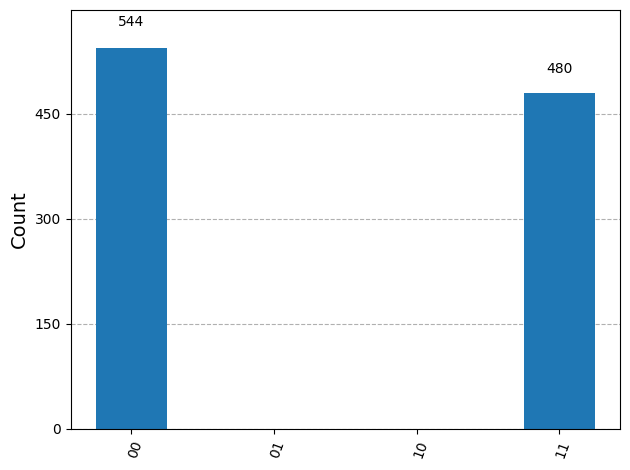

In [ ]:
plot_histogram(qubit_counts_bell | {'01': 0, '10': 0})

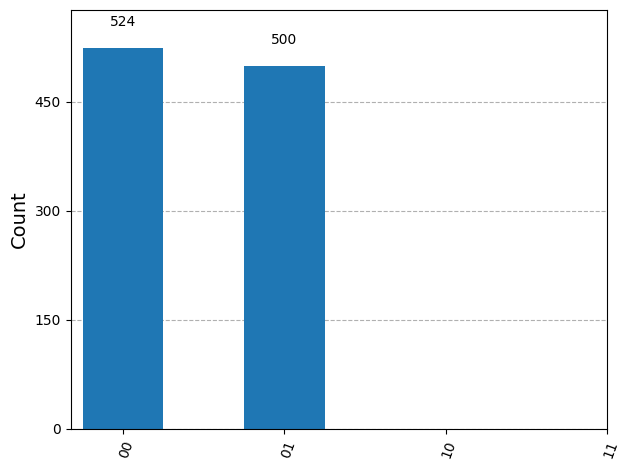

In [ ]:
plot_histogram(qubit_counts_original | {'10': 0, '11': 0})


We can see that the qubits are always in the same state: either `1` or either `0` about 50% of the time.

> References:
> * https://docs.quantum.ibm.com/guides/post-process-results

---
# Executing in a real backend

In the previous sections we have used a local simulator (`qiskit_aer`) as the backend where we executed the Quantum Circuits agains. For more complex circuits, we need to use real devices.

IBM provides access to multiple Quantum Devices for free:

1. Create an account in IBM Quantum: https://quantum.ibm.com
2. Once create, create an API token: https://quantum.ibm.com/account

With those credentials, we instantiate the object that represents the remote service:

In [ ]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService(
    channel='ibm_quantum',
    token='MI_TOKEN',
    instance='ibm-q/open/main',
)

# Form July 1st, this instead:
# service = QiskitRuntimeService(
#     channel="ibm_cloud",
#     token="MI_API_KEY",
#     instance="MI_INSTANCIA_CRN"
# )


/tmp/ipython-input-13-643690628.py:11: DeprecationWarning: The "ibm_quantum" channel option is deprecated and will be sunset on 1 July. After this date, "ibm_cloud", "ibm_quantum_platform", and "local" will be the only valid channels. Open Plan users should migrate now.  All other users should review the migration guide (https://quantum.cloud.ibm.com/docs/migration-guides/classic-iqp-to-cloud-iqp)to learn when to migrate.
  service = QiskitRuntimeService(


In [ ]:
from qiskit_ibm_runtime import QiskitRuntimeService


# Only works in this notebook, with a secret set up.
from google.colab import userdata
service = QiskitRuntimeService(
    channel='ibm_quantum',
    token=userdata.get('API_KEY'),
    instance='ibm-q/open/main',
)

/tmp/ipython-input-27-2836592122.py:6: DeprecationWarning: The "ibm_quantum" channel option is deprecated and will be sunset on 1 July. After this date, "ibm_cloud", "ibm_quantum_platform", and "local" will be the only valid channels. Open Plan users should migrate now.  All other users should review the migration guide (https://quantum.cloud.ibm.com/docs/migration-guides/classic-iqp-to-cloud-iqp)to learn when to migrate.
  service = QiskitRuntimeService(


Once the `QiskitRuntimeService` is created, you can send Quantum Circuits to the real Quantum Devices. In order to do so, the steps are very similar - in step 3, when creating the Primitive, we can instead use a real backend, in particular the one that has less load:

In [ ]:
from qiskit_ibm_runtime import SamplerV2 as Sampler

backend = service.least_busy(operational=True, simulator=False)

sampler = Sampler(backend)

We can check out what backend was assigned to us:

In [ ]:
backend

<IBMBackend('ibm_sherbrooke')>

We need to optimize the circuit for this particular backend, same as we did in step 2:

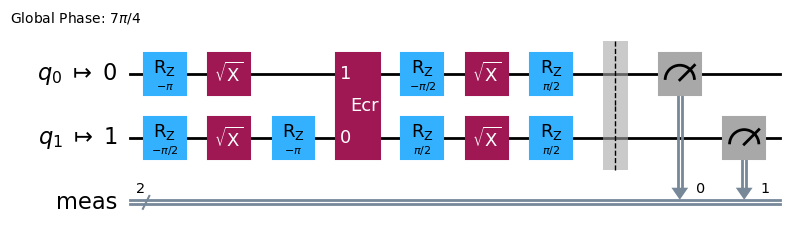

In [ ]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_circuit_bell = pm.run(circuito_bell)

isa_circuit_bell.draw("mpl", idle_wires=False)

And finally, we can execute it just as we did against the simulator:

In [ ]:
job = sampler.run([isa_circuit_bell])
print(f"job id: {job.job_id()}")

job id: d1aps14mya70008nbefg


/usr/local/lib/python3.11/dist-packages/qiskit_ibm_runtime/qiskit_runtime_service.py:1129: UserWarning: IBM Quantum Platform is moving, and this version will be sunset on July 1. To get started on the new platform, read the migration guide at https://docs.quantum.ibm.com/migration-guides/classic-iqp-to-cloud-iqp
  warnings.warn(warning_message)


After calling this function, the Quantum Circuits gets sent to the real device, entering a queue. You can check the state of your job in the web platform as well as programmatically: https://quantum.ibm.com/workloads.

From a Python point of view, retrieving the results of a job is a blocking operation: in the next cell, `.result()` will only finish when the job has finished, so it can take a few minutes:

In [ ]:
result = job.result()
print(result)

PrimitiveResult([SamplerPubResult(data=DataBin(meas=BitArray(<shape=(), num_shots=4096, num_bits=2>)), metadata={'circuit_metadata': {}})], metadata={'execution': {'execution_spans': ExecutionSpans([DoubleSliceSpan(<start='2025-06-20 14:13:28', stop='2025-06-20 14:13:30', size=4096>)])}, 'version': 2})


Finally, this is the result of executing your circuit against a real quantum computer.

In [ ]:
qubit_counts_real = result[0].data.meas.get_counts()
qubit_counts_real

{'01': 351, '00': 1832, '11': 1660, '10': 253}

---
# Next steps and resources

* https://docs.quantum-computing.ibm.com/
* https://docs.quantum.ibm.com/api/qiskit
* https://learning.quantum-computing.ibm.com/
* https://www.ibm.com/quantum/quantum-safe
* https://www.youtube.com/qiskit